# Follow-up Lab: Decision Trees versus Naïve Bayes

In the previous lab, you built a Naïve Bayes classifier for the same question:

> Can we predict whether a name is labeled male or female?

You also developed the final feature function, gender_features5. In this follow-up, we will **keep the data, the train/dev-test/test split, and the features exactly the same**. The only major change is the classifier: we will replace Naïve Bayes with an NLTK decision tree.

We will then compare the two models:

- What features does each model find informative?
- Which model performs better?
- How do their accuracy, precision, recall, and F1 scores differ?
**New continuation: Sections 8–15 add a scikit-learn random forest, hyperparameter tuning, and a final comparison.** Run the notebook from the beginning; it includes all required data preparation.

The target is the male/female label recorded in NLTK's names corpus. This exercise predicts dataset labels from spelling; a name does not determine a person's gender.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
import random
import nltk

# Reuse a local copy when available; otherwise download the names corpus.
try:
    nltk.data.find('corpora/names.zip')
except LookupError:
    nltk.download('names', raise_on_error=True)

In [3]:
from nltk.corpus import names

In [4]:
labeled_names = ([(name, 'male') for name in names.words('male.txt')] + [(name, 'female') for name in names.words('female.txt')])

In [5]:
random.Random(2026).shuffle(labeled_names)

In [10]:
train_names = labeled_names[1500:]
devtest_names = labeled_names[500:1500]
test_names = labeled_names[:500]

In [9]:
def gender_features5(name):
  features = {}
  features["first_letter"] = name[0].lower()
  features["last_letter"] = name[-1].lower()
  features["suffix"]= name[-2:].lower()
  features["length"] = len(name)

  for letter in 'abcdefghijklmnopqrstuvwxyz':
    features["count({})".format(letter)] = name.lower().count(letter)
  return features

In [11]:
train_set = [(gender_features5(n), gender) for (n, gender) in train_names]
devtest_set = [(gender_features5(n), gender) for (n, gender) in devtest_names]
test_set = [(gender_features5(n), gender) for (n, gender) in test_names]

## 1. Recreate the previous Naïve Bayes model

The previous lab already trained a Naïve Bayes model with these feature dictionaries. We retrain it here under a clearer name so that we can compare it directly with the new decision-tree model.

There is no new feature engineering in this section.


In [12]:
from nltk.classify import NaiveBayesClassifier

nb_classifier = NaiveBayesClassifier.train(train_set)

print('Naïve Bayes development accuracy:',
      nltk.classify.accuracy(nb_classifier, devtest_set))


Naïve Bayes development accuracy: 0.772


## 2. Replace the classifier with an NLTK decision tree

Unlike a scikit-learn decision tree, NLTK's decision tree accepts the same feature dictionaries that Naïve Bayes uses. This means we do not need a feature-to-column conversion step.

The setting binary=True asks the tree to consider questions such as:

    Is suffix equal to yn?

This makes the tree's decisions easy to compare with the feature-value evidence reported by Naïve Bayes.


In [13]:
from nltk.classify import DecisionTreeClassifier

tree_classifier = DecisionTreeClassifier.train(train_set, binary=True, depth_cutoff=8)

print('Decision-tree development accuracy:',
      nltk.classify.accuracy(tree_classifier, devtest_set))


Decision-tree development accuracy: 0.752


## 3. Inspect the decision tree

The tree's upper levels contain its earliest and usually most influential decisions. We display the upper levels using NLTK's own tree-formatting function.


In [14]:
print(tree_classifier.pseudocode(depth=2))


if last_letter == 'd': 
  if count(a) == 3: return 'female'
  if count(a) != 3: return 'male'
if last_letter != 'd': 
  if last_letter == 'r': return 'male'
  if last_letter != 'r': return 'male'



## 4. Compare the most informative features

Naïve Bayes and a decision tree do not define feature importance in exactly the same way.

- Naïve Bayes reports feature-value pairs with large likelihood ratios.
- The decision tree places highly useful split features near the top of the tree.


In [15]:
nb_classifier.show_most_informative_features(5)

Most Informative Features
                  suffix = 'na'           female : male   =    144.5 : 1.0
                  suffix = 'ia'           female : male   =     48.1 : 1.0
                  suffix = 'ld'             male : female =     36.1 : 1.0
             last_letter = 'k'              male : female =     35.0 : 1.0
             last_letter = 'a'            female : male   =     34.7 : 1.0


### Interpretation

Compare the Naïve Bayes table with the decision-tree display.

1. Which feature-value pairs are informative for Naïve Bayes?
2. What is the decision tree's first split?
3. Do the two models focus on the same evidence? Why might their rankings differ even though they use exactly the same feature dictionaries?


# Your Turn

Make a non-binary tree and inspect the first feature of the tree's split. What is the most useful feature this time?

## 5. Generate predictions on the same test set

Both models now classify exactly the same test feature dictionaries.


In [16]:
# Gold labels
gold = [label for features, label in test_set]

# Feature dictionaries for the test set
test_features = [features for features, label in test_set]

# Predictions from NLTK models
nb_predictions = nb_classifier.classify_many(test_features)
tree_predictions = tree_classifier.classify_many(test_features)

print('First 5 gold labels: ', gold[:5])
print('First 5 Naïve Bayes predictions: ', nb_predictions[:5])
print('First 5 decision-tree predictions:', tree_predictions[:5])


First 5 gold labels:  ['male', 'male', 'male', 'female', 'female']
First 5 Naïve Bayes predictions:  ['male', 'female', 'male', 'female', 'female']
First 5 decision-tree predictions: ['male', 'female', 'male', 'female', 'female']


For precision, recall, and F1, we use the package of sklearn. We calculate the score for male and female separately and then take the macro average.


In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

In [18]:
precision_score(gold, nb_predictions, average='macro')

0.8020148060213352

In [19]:
precision_score(gold, tree_predictions, average='macro')

0.777355623100304

In [20]:
precision_score(gold, nb_predictions, average='micro')

0.812

In [21]:
precision_score(gold, tree_predictions, average='micro')

0.738

In [22]:
recall_score(gold, nb_predictions, average='macro')

0.8079865489701555

In [23]:
def evaluate_model(gold, predictions):
    return {
        'accuracy': accuracy_score(gold, predictions),
        'precision': precision_score(
            gold, predictions, average='macro'
        ),
        'recall': recall_score(
            gold, predictions, average='macro'
        ),
        'f1': f1_score(
            gold, predictions, average='macro'
        ),
    }

metrics_df = pd.DataFrame([
    {
        'model': 'Naïve Bayes',
        **evaluate_model(gold, nb_predictions),
    },
    {
        'model': 'Decision Tree',
        **evaluate_model(gold, tree_predictions),
    },
])

metrics_df.round(3)

,model,accuracy,precision,recall,f1
0,Naïve Bayes,0.812,0.802,0.808,0.804
1,Decision Tree,0.738,0.777,0.678,0.681


## 7. How does tree depth affect performance?

This is still the same decision-tree algorithm and the same feature dictionaries. We only change the depth cutoff.

Compare **training and development accuracy**. A very shallow tree may underfit; a very deep tree may overfit. Use development performance to choose settings; do not inspect test performance for each candidate.


In [ ]:
depth_results = []

for depth in [1, 3, 6, 9, 12, 18]:
    model = DecisionTreeClassifier.train(
        train_set,
        binary=True,
        depth_cutoff=depth,
    )

    training_accuracy = nltk.classify.accuracy(model, train_set)
    development_accuracy = nltk.classify.accuracy(model, devtest_set)
    test_accuracy = nltk.classify.accuracy(model, test_set)

    depth_results.append({
        'depth_cutoff': depth,
        'training_accuracy': training_accuracy,
        'development_accuracy': development_accuracy,
        'test_accuracy': test_accuracy,
    })

depth_df = pd.DataFrame(depth_results)
depth_df.round(3)

,depth_cutoff,training_accuracy,development_accuracy
0,1,0.655,0.652
1,3,0.692,0.680
2,6,0.744,0.719
3,9,0.778,0.756
4,12,0.796,0.762
5,18,0.812,0.774


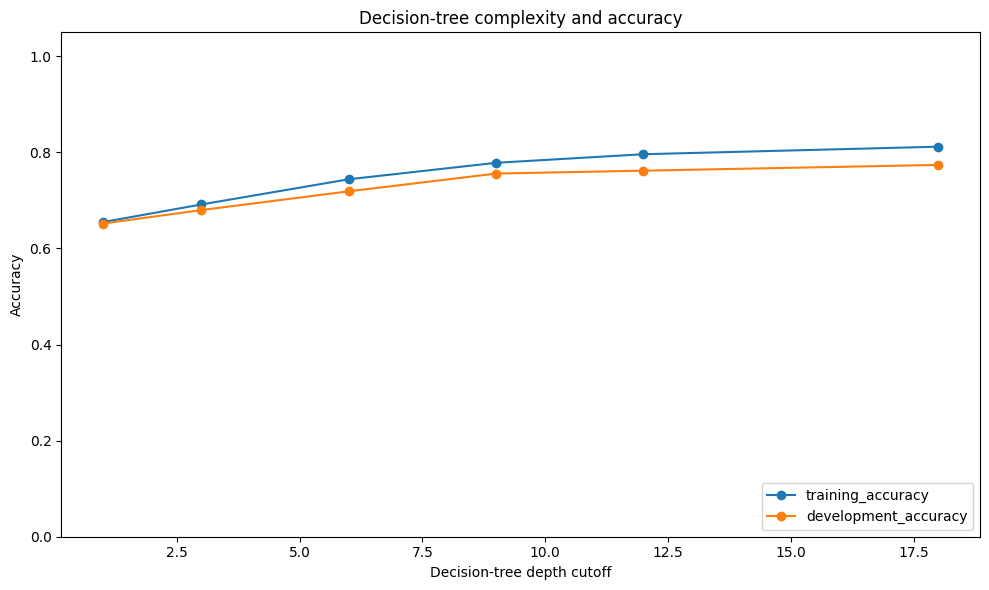

In [ ]:
depth_plot = depth_df.set_index('depth_cutoff')
depth_plot.plot(marker='o', figsize=(10, 6))
plt.ylim(0, 1.05)
plt.ylabel('Accuracy')
plt.xlabel('Decision-tree depth cutoff')
plt.title('Decision-tree complexity and accuracy')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


## Reflection: Naïve Bayes and decision trees

1. Which model performed better on the unseen test set?
2. Which feature-value pairs were most informative for Naïve Bayes?
3. What feature did the decision tree use for its first split?
4. Did the two models focus on the same evidence?
5. What do the precision, recall, F1, and confusion matrices reveal that accuracy alone does not?
6. What pattern do you see as the decision-tree depth increases?


## 8. Continue with a random forest

A random forest combines many decision trees. With the settings used here:

1. Each tree trains on a random sample of training examples **with replacement** (a bootstrap sample).
2. At each split, the tree considers a random subset of the feature columns.
3. Scikit-learn averages the trees' class probabilities and predicts the class with the highest average probability.

We use **scikit-learn** for this model. We keep `gender_features5`, `train_set`, `devtest_set`, and `test_set` from above.

| Data | Purpose in this continuation |
|---|---|
| Training | Learn the vectorizer's columns and fit each forest |
| Development | Compare hyperparameter settings using macro F1 |
| Test | Compare the fixed models after tuning is finished |

The earlier lab has already shown this test set's results. We reuse it for classroom continuity, but it is not a newly collected, untouched benchmark. Do not use its results to change the random forest settings.


In [26]:
# Import the forest and the tool that converts dictionaries into numeric columns.
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction import DictVectorizer

# ParameterGrid will generate combinations of settings for our tuning loop.
from sklearn.model_selection import ParameterGrid

# Display tables clearly in Jupyter or Colab.
from IPython.display import display


### Convert the existing feature dictionaries into numbers

Scikit-learn needs a numeric feature matrix. `DictVectorizer` turns string values into indicator columns: for example, `last_letter=a` is 1 when a name ends in *a* and 0 otherwise. Numeric features such as `length` and `count(a)` remain numbers.

**Fit the vectorizer on training dictionaries only.** Reuse that mapping to transform development and test data. A category absent from training does not create a new column later. `X` holds features; `y` holds labels.

These are the same underlying features as before, but the implementation differs: scikit-learn can split numeric counts at thresholds, while the earlier NLTK binary tree tests feature-value equality. Therefore, the final comparison is not a controlled test of ensembling alone.


In [28]:
# Separate each split into a list of feature dictionaries and a list of labels.
train_features = [features for features, label in train_set]
dev_features = [features for features, label in devtest_set]
test_features = [features for features, label in test_set]
y_train = [label for features, label in train_set]
y_dev = [label for features, label in devtest_set]
y_test = [label for features, label in test_set]

# Learn the column mapping from training data and retain a sparse matrix.
vectorizer = DictVectorizer(sparse=True)
X_train = vectorizer.fit_transform(train_features)

# Apply the training mapping to the other splits without fitting again.
X_dev = vectorizer.transform(dev_features)
X_test = vectorizer.transform(test_features)

# Inspect the matrix dimensions and the actual feature-column names.
print('Training shape:', X_train.shape)
print('Development shape:', X_dev.shape)
print('Test shape:', X_test.shape)
print('Feature columns:', vectorizer.get_feature_names_out().tolist())

# Show five rows and a few columns; densify only this small preview.
preview_columns = ['length', 'count(a)', 'last_letter=a', 'suffix=na']
preview_indices = [vectorizer.vocabulary_[column] for column in preview_columns]
display(pd.DataFrame(
    X_train[:5, preview_indices].toarray(),
    index=[name for name, label in train_names[:5]],
    columns=preview_columns,
))


Training shape: (6444, 336)
Development shape: (1000, 336)
Test shape: (500, 336)
Feature columns: ['count(a)', 'count(b)', 'count(c)', 'count(d)', 'count(e)', 'count(f)', 'count(g)', 'count(h)', 'count(i)', 'count(j)', 'count(k)', 'count(l)', 'count(m)', 'count(n)', 'count(o)', 'count(p)', 'count(q)', 'count(r)', 'count(s)', 'count(t)', 'count(u)', 'count(v)', 'count(w)', 'count(x)', 'count(y)', 'count(z)', 'first_letter=a', 'first_letter=b', 'first_letter=c', 'first_letter=d', 'first_letter=e', 'first_letter=f', 'first_letter=g', 'first_letter=h', 'first_letter=i', 'first_letter=j', 'first_letter=k', 'first_letter=l', 'first_letter=m', 'first_letter=n', 'first_letter=o', 'first_letter=p', 'first_letter=q', 'first_letter=r', 'first_letter=s', 'first_letter=t', 'first_letter=u', 'first_letter=v', 'first_letter=w', 'first_letter=x', 'first_letter=y', 'first_letter=z', 'last_letter=a', 'last_letter=b', 'last_letter=c', 'last_letter=d', 'last_letter=e', 'last_letter=f', 'last_letter=g', '

,length,count(a),last_letter=a,suffix=na
Zorana,6.0,2.0,1.0,1.0
Hyacinthe,9.0,1.0,0.0,0.0
Stanley,7.0,1.0,0.0,0.0
Sigrid,6.0,0.0,0.0,0.0
Kim,3.0,0.0,0.0,0.0


## 9. Train a baseline random forest

Start with 100 trees. We set the main hyperparameters explicitly so you can see what to change. `random_state` makes the random sampling reproducible in the same environment. `n_jobs=-1` allows the model to use all available CPU cores; neither setting is a model-complexity control.


In [29]:
# Create a forest with explicit starting settings.
rf_baseline = RandomForestClassifier(
    n_estimators=100,       # Number of trees in the forest.
    max_depth=None,        # No explicit depth limit for individual trees.
    min_samples_split=2,   # A node needs at least 2 examples to attempt a split.
    min_samples_leaf=1,    # Each resulting leaf needs at least 1 example.
    max_features='sqrt',   # Consider roughly sqrt(number of columns) per split.
    criterion='gini',      # Evaluate candidate splits using Gini impurity.
    bootstrap=True,        # Sample training examples with replacement per tree.
    random_state=2026,     # Fix the random seed for reproducibility.
    n_jobs=-1,             # Use available CPU cores.
)

# Learn the trees from the training features and labels.
rf_baseline.fit(X_train, y_train)

# Evaluate training and development predictions; do not tune on the test set.
rf_train_predictions = rf_baseline.predict(X_train).tolist()
rf_dev_predictions = rf_baseline.predict(X_dev).tolist()
print('Training macro F1:', round(f1_score(y_train, rf_train_predictions, average='macro'), 3))
print('Development macro F1:', round(f1_score(y_dev, rf_dev_predictions, average='macro'), 3))


Training macro F1: 0.959
Development macro F1: 0.763


## 10. What do the hyperparameters control?

Hyperparameters are settings we choose **before fitting**. Split features, thresholds, and leaf probabilities are learned during fitting.

| Hyperparameter | Meaning | Values to explore / likely effect |
|---|---|---|
| `n_estimators` | Number of trees | 100 or 200. More trees usually stabilize predictions but cost more time; they do not make each tree deeper. |
| `max_depth` | Maximum depth of each tree | 4, 8, 16, or `None`. Small limits can underfit; large limits allow more complex trees. `None` removes this limit, not other stopping conditions. |
| `min_samples_leaf` | Minimum examples in each leaf | 1, 3, or 5. Larger values prevent very small leaves and can reduce overfitting. |
| `min_samples_split` | Minimum examples at a node before it may split | 2, 5, or 10. This differs from requiring a minimum in **both resulting leaves**. |
| `max_features` | Number of feature columns considered at each split | `'sqrt'` or `0.5` (half the columns). Smaller subsets increase randomness; the best tradeoff depends on the data. |
| `criterion` | Impurity measure used to judge splits | `'gini'` or `'entropy'`. This is separate from the macro F1 score used to choose the best complete model. |

`max_features` refers to the **vectorized columns**, including separate suffix and letter indicators. `max_depth` is conceptually similar to NLTK's `depth_cutoff`, but their values do not imply identical trees.

**Tuning procedure:** fit candidates on training data → score them on development data → choose settings → evaluate the fixed model on test data. Macro F1 is our selection metric because it gives the two labels equal weight. It averages the class-specific F1 scores.


## 11. Tune one hyperparameter: maximum depth

First hold all other settings fixed. Compare training and development macro F1 as each tree is allowed to grow deeper. High training performance with weaker development performance can indicate overfitting. Adding trees and increasing tree depth are different changes.


,max_depth,training_macro_f1,development_macro_f1
0,2,0.387,0.388
1,4,0.531,0.507
2,8,0.718,0.688
3,12,0.789,0.734
4,20,0.900,0.770
5,None,0.959,0.763


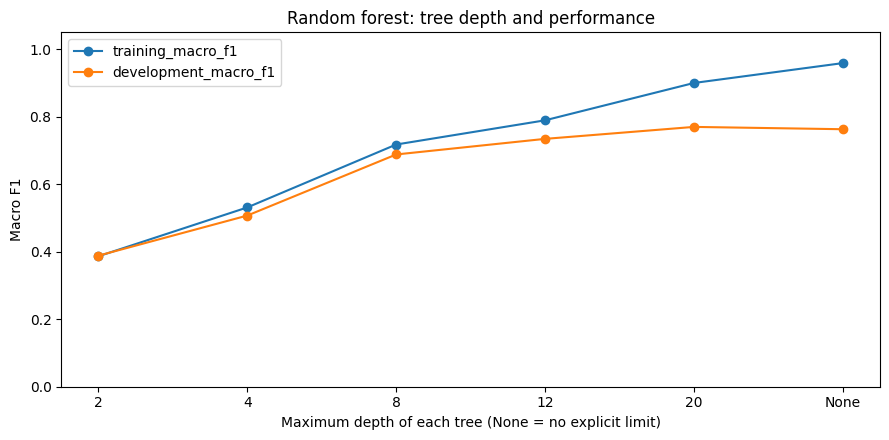

In [30]:
# Try six depth limits while keeping the other settings the same.
rf_depth_results = []
for depth in [2, 4, 8, 12, 20, None]:
    model = RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        min_samples_leaf=1,
        max_features='sqrt',
        random_state=2026,
        n_jobs=-1,
    )
    # Fit only on training examples.
    model.fit(X_train, y_train)

    # Store training and development scores for this depth.
    rf_depth_results.append({
        'max_depth': str(depth),
        'training_macro_f1': f1_score(y_train, model.predict(X_train), average='macro'),
        'development_macro_f1': f1_score(y_dev, model.predict(X_dev), average='macro'),
    })

# Show the scores numerically and as a learning-complexity plot.
rf_depth_df = pd.DataFrame(rf_depth_results)
display(rf_depth_df.round(3))
rf_depth_df.set_index('max_depth').plot(marker='o', figsize=(9, 4.5))
plt.xlabel('Maximum depth of each tree (None = no explicit limit)')
plt.ylabel('Macro F1')
plt.ylim(0, 1.05)
plt.title('Random forest: tree depth and performance')
plt.tight_layout()
plt.show()


### Your turn

1. Which depth has the best development macro F1? Is it also the best on training data?
2. Where do you see underfitting or a gap between training and development performance?
3. Before running the next section, predict what increasing `min_samples_leaf` might do to that gap.


## 12. Tune several hyperparameters with a small grid search

`ParameterGrid` creates every combination in the dictionary below. There are **2 × 3 × 2 × 2 = 24 candidate forests**. The loop makes the search explicit: fit, predict, score, and retain the best model.

This is a **grid search with a fixed development set**, not cross-validation. It uses the split already provided in this lab. It can take a few minutes; for a quicker trial, use only `[100]` for `n_estimators`.

We keep the other settings fixed. The winning model is the best **among these candidates on this development set**, not necessarily the best possible forest. Tuning is not guaranteed to improve on the baseline.


In [31]:
# Specify the candidate values for four hyperparameters.
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [8, 16, None],
    'min_samples_leaf': [1, 3],
    'max_features': ['sqrt', 0.5],
}

# Prepare the results table and variables that will retain the best fitted model.
candidates = list(ParameterGrid(param_grid))
search_rows = []
best_dev_f1 = -1.0
best_params = None
best_rf = None

# Fit one forest for each combination; **params unpacks the settings dictionary.
for candidate_number, params in enumerate(candidates, start=1):
    candidate = RandomForestClassifier(
        **params,
        criterion='gini',
        min_samples_split=2,
        bootstrap=True,
        random_state=2026,
        n_jobs=-1,
    )
    candidate.fit(X_train, y_train)

    # Development macro F1 is the only score used to select a winner.
    dev_predictions = candidate.predict(X_dev)
    dev_f1 = f1_score(y_dev, dev_predictions, average='macro')
    train_f1 = f1_score(y_train, candidate.predict(X_train), average='macro')

    # Preserve the actual Python parameters, including None, in best_params.
    if dev_f1 > best_dev_f1:
        best_dev_f1 = dev_f1
        best_params = params.copy()
        best_rf = candidate

    # Store display-friendly settings and diagnostic scores for each candidate.
    search_rows.append({
        'candidate': candidate_number,
        **{key: ('None' if value is None else value) for key, value in params.items()},
        'training_macro_f1': train_f1,
        'development_macro_f1': dev_f1,
    })
    print(f'Candidate {candidate_number:02d}/{len(candidates)}: development macro F1 = {dev_f1:.3f}')

# Rank the settings by development score; tied scores retain search order.
tuning_results = pd.DataFrame(search_rows).sort_values(
    'development_macro_f1', ascending=False, kind='stable'
)
display(tuning_results.round(3))
print('Selected settings:', best_params)
print('Best development macro F1:', round(best_dev_f1, 3))


Candidate 01/24: development macro F1 = 0.688
Candidate 02/24: development macro F1 = 0.695
Candidate 03/24: development macro F1 = 0.692
Candidate 04/24: development macro F1 = 0.689
Candidate 05/24: development macro F1 = 0.766
Candidate 06/24: development macro F1 = 0.762
Candidate 07/24: development macro F1 = 0.765
Candidate 08/24: development macro F1 = 0.760
Candidate 09/24: development macro F1 = 0.764
Candidate 10/24: development macro F1 = 0.756
Candidate 11/24: development macro F1 = 0.754
Candidate 12/24: development macro F1 = 0.757
Candidate 13/24: development macro F1 = 0.786
Candidate 14/24: development macro F1 = 0.781
Candidate 15/24: development macro F1 = 0.793
Candidate 16/24: development macro F1 = 0.794
Candidate 17/24: development macro F1 = 0.763
Candidate 18/24: development macro F1 = 0.771
Candidate 19/24: development macro F1 = 0.780
Candidate 20/24: development macro F1 = 0.791
Candidate 21/24: development macro F1 = 0.769
Candidate 22/24: development macro

,candidate,max_depth,max_features,min_samples_leaf,n_estimators,training_macro_f1,development_macro_f1
15,16,16,0.5,3,200,0.867,0.794
14,15,16,0.5,3,100,0.866,0.793
22,23,None,0.5,3,100,0.904,0.791
23,24,None,0.5,3,200,0.904,0.791
19,20,None,sqrt,3,200,0.845,0.791
12,13,16,0.5,1,100,0.903,0.786
13,14,16,0.5,1,200,0.904,0.781
18,19,None,sqrt,3,100,0.843,0.780
17,18,None,sqrt,1,200,0.959,0.771
20,21,None,0.5,1,100,0.959,0.769


Selected settings: {'max_depth': 16, 'max_features': 0.5, 'min_samples_leaf': 3, 'n_estimators': 200}
Best development macro F1: 0.794


### Reading the search results

- Compare the top candidate's training and development scores. High training F1 alone is not a reason to select it.
- When scores tie exactly, this loop keeps the first candidate encountered. Small differences on one split should not be overinterpreted.
- `best_rf` is already fitted. We retain training-only fitting so every model in the final comparison has the same training examples.
- For another experiment, you could add `'criterion': ['gini', 'entropy']` to `param_grid` and **remove `criterion='gini'` from the constructor** to avoid passing it twice. This doubles the search to 48 candidates. Choose your search plan before looking at test scores.
- For a later lesson, `GridSearchCV` can compare settings across multiple training folds. Put `DictVectorizer` inside a `Pipeline` so each fold learns its own mapping. Keep the final test set separate.


## 13. Final comparison on the same test set

The settings are now fixed. Compare Naïve Bayes, the original NLTK decision tree, the baseline random forest, and the tuned random forest on the same 500 examples. The model names identify the different implementations.

Do not change the selected settings after seeing this table. A development-set gain need not carry over to the test set.


,accuracy,macro_precision,macro_recall,macro_f1
model,,,,
Naïve Bayes (NLTK),0.812,0.802,0.808,0.804
Decision tree (NLTK),0.738,0.777,0.678,0.681
Random forest: baseline,0.830,0.824,0.815,0.819
Random forest: tuned,0.832,0.825,0.820,0.822


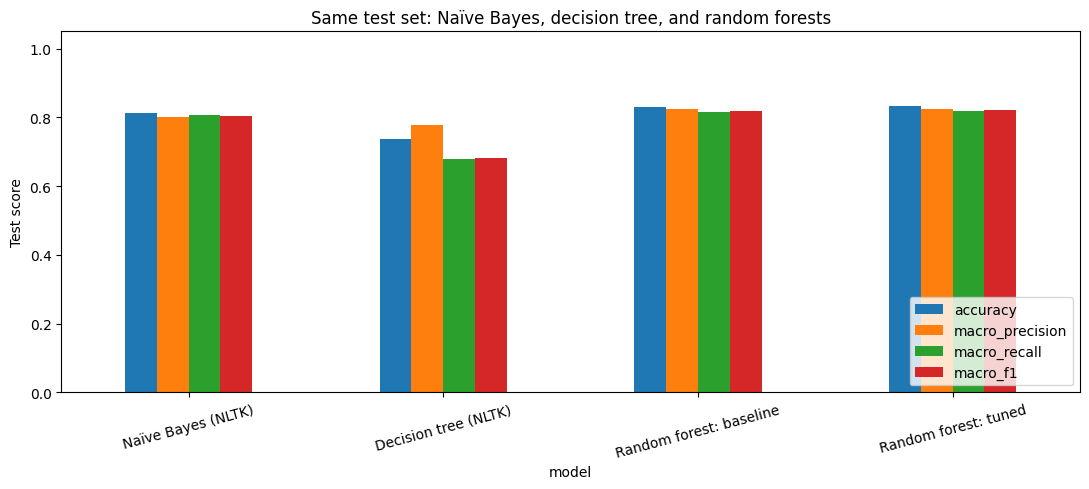

,name,gold,naive_bayes,decision_tree,random_forest,tuned_random_forest
0,Stephanus,male,male,male,male,male
1,Johnny,male,female,female,male,female
2,Caspar,male,male,male,male,male
3,Toma,female,female,female,female,female
4,Lynsey,female,female,female,female,female
5,Duane,male,female,female,female,female
6,Lina,female,female,female,female,female
7,Gabriel,male,male,female,female,female
8,Patsy,female,female,female,male,female
9,Ricard,male,male,male,male,male


In [34]:
# Generate plain prediction lists, in the same order as the gold-label list.
gold = y_test
nb_predictions = nb_classifier.classify_many(test_features)
tree_predictions = tree_classifier.classify_many(test_features)
rf_predictions = rf_baseline.predict(X_test).tolist()
tuned_rf_predictions = best_rf.predict(X_test).tolist()

# Reuse evaluate_model from the earlier lab for accuracy and macro P/R/F1.
model_predictions = {
    'Naïve Bayes (NLTK)': nb_predictions,
    'Decision tree (NLTK)': tree_predictions,
    'Random forest: baseline': rf_predictions,
    'Random forest: tuned': tuned_rf_predictions,
}
comparison_rows = []
for model_name, predictions in model_predictions.items():
    comparison_rows.append({'model': model_name, **evaluate_model(gold, predictions)})

# Name the macro-averaged metrics explicitly in the output table.
comparison_df = pd.DataFrame(comparison_rows).set_index('model').rename(columns={
    'precision': 'macro_precision', 'recall': 'macro_recall', 'f1': 'macro_f1',
})
display(comparison_df.round(3))

# Plot the same numerical results for a visual comparison.
comparison_df.plot.bar(figsize=(11, 5), rot=15)
plt.ylabel('Test score')
plt.ylim(0, 1.05)
plt.title('Same test set: Naïve Bayes, decision tree, and random forests')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# Inspect individual predictions alongside the name and its dataset label.
prediction_table = pd.DataFrame({
    'name': [name for name, label in test_names],
    'gold': gold,
    'naive_bayes': nb_predictions,
    'decision_tree': tree_predictions,
    'random_forest': rf_predictions,
    'tuned_random_forest': tuned_rf_predictions,
})
display(prediction_table.head(15))


              precision    recall  f1-score   support

      female      0.853     0.875     0.864       305
        male      0.797     0.764     0.780       195

    accuracy                          0.832       500
   macro avg      0.825     0.820     0.822       500
weighted avg      0.831     0.832     0.831       500



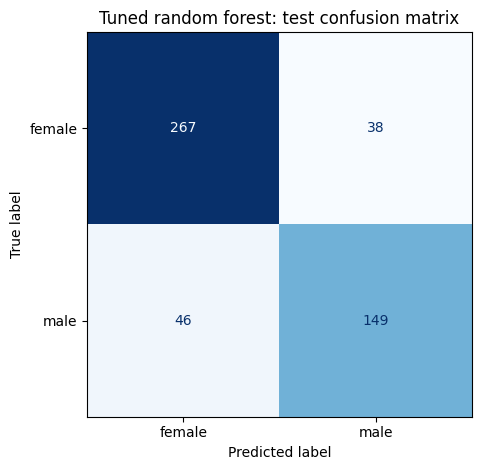

In [35]:
# Inspect per-label scores and errors for the selected random forest.
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

print(classification_report(gold, tuned_rf_predictions, digits=3, zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    gold, tuned_rf_predictions,
    labels=['female', 'male'],
    cmap='Blues', colorbar=False,
)
plt.title('Tuned random forest: test confusion matrix')
plt.tight_layout()
plt.show()


## 14. Which features does the forest use?

`feature_importances_` summarizes the normalized, weighted impurity reductions attributed to each column across the trees. Larger values mean a column contributed more to these training splits. They do **not** indicate whether the feature favors male or female, and they are not directly comparable to Naïve Bayes likelihood ratios.

These training-based importances can favor features with more possible split points. Correlated columns (such as last letter and suffix) can share importance. Treat them as a description of the fitted forest, not a causal explanation.


,feature,importance
52,last_letter=a,0.2336
56,last_letter=e,0.0980
60,last_letter=i,0.0594
77,length,0.0416
24,count(y),0.0378
4,count(e),0.0302
0,count(a),0.0295
8,count(i),0.0260
22,count(w),0.0180
17,count(r),0.0175


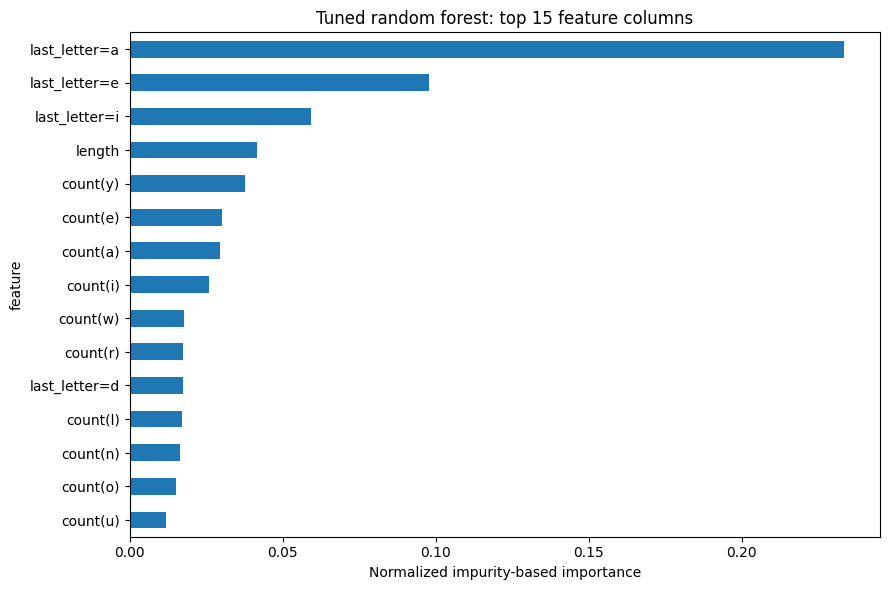

In [36]:
# Match each importance value to the corresponding vectorizer column.
importance_df = pd.DataFrame({
    'feature': vectorizer.get_feature_names_out(),
    'importance': best_rf.feature_importances_,
}).sort_values('importance', ascending=False)

# Display and plot the 15 highest-ranked columns.
display(importance_df.head(15).round(4))
importance_df.head(15).sort_values('importance').plot.barh(
    x='feature', y='importance', legend=False, figsize=(9, 6),
)
plt.xlabel('Normalized impurity-based importance')
plt.title('Tuned random forest: top 15 feature columns')
plt.tight_layout()
plt.show()


## 15. Reflection and limitations

1. Which random forest hyperparameters were selected? Explain what each selected value means.
2. Did tuning improve development macro F1? Did the same change appear on the test set?
3. Why is increasing `n_estimators` different from increasing `max_depth`?
4. Why do we fit the vectorizer on training data only?
5. Which features overlap with the evidence used by Naïve Bayes and the decision tree?
6. Which kinds of errors appear in the confusion matrix? What might explain names that receive different predictions from different models?

**Scope of this comparison:** We preserve the original shuffled row split. A spelling can occur in both label lists and therefore potentially in more than one split. These scores do not establish performance on entirely unseen name spellings or on other populations. A future experiment could group identical spellings before splitting; that would change the original train/dev/test sets and require rerunning every model.

**References**

- [RandomForestClassifier: settings, probabilities, and feature importance](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)
- [DictVectorizer: converting feature dictionaries](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.DictVectorizer.html)
- [ParameterGrid: generating parameter combinations](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.ParameterGrid.html)
